# Malaria Detection from Blood-Cell Images
### Transfer Learning with ResNet-18 | Week 6

| Item | Detail |
|---|---|
| **Name** | [Anderia Nisar] |
| **Subject** | Introduction to Applied AI |
| **Project** | Project 2: Deep Learning Applications |
| **Dataset** | Cell Images for Detecting Malaria (NIH, via Kaggle) |
| **Task** | Binary classification: Parasitized vs Uninfected |
| **Model** | ResNet-18 pretrained on ImageNet, fine-tuned in two phases |

**Notebook roadmap**

| Section | Topic |
|---|---|
| 1 | Data understanding and audit |
| 2 | Leakage checks and patient-level split |
| 3 | Preprocessing, augmentation and class weights |
| 4 | Two-phase training |
| 5 | Test evaluation and threshold selection |
| 6 | Explainability with Grad-CAM |
| 7 | Model export |
| 8 | Review questions |

In [1]:

DATA_ROOT = '/kaggle/input/datasets/anderianisar/malaria-detection/cell_images'
TRAIN_DIR = f'{DATA_ROOT}/cell_images'   # folder with one subfolder per class
TEST_DIR = None                          # no test folder: code carves a grouped test set
GRAYSCALE = False                        # stained blood-cell images are colour
IMG_SIZE = 224
BACKBONE = 'resnet18'                    # or 'resnet50', 'efficientnet_b0'
# Patient id = leading 'C' + digits, e.g. C100P61ThinF_IMG_... -> C100
GROUP_PATTERN = r'^(C\d+)'               # None if no groups
POSITIVE = 'Parasitized'                 # binary tasks: the class you must catch
TARGET_RECALL = 0.95                     # binary tasks: recall you must reach
# ======================================================================

In [2]:
import os
import re
import time
import copy
import hashlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             roc_auc_score, roc_curve)

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
print('Classes found:', sorted(os.listdir(TRAIN_DIR)))

Device: cuda
Classes found: ['Parasitized', 'Uninfected']


In [3]:
def index_folder(folder):
    """One row per image: path, class label, file name, group id."""
    rows = []
    for cls in sorted(os.listdir(folder)):
        cdir = os.path.join(folder, cls)
        if not os.path.isdir(cdir):
            continue
        for f in sorted(os.listdir(cdir)):
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif')):
                rows.append({'path': os.path.join(cdir, f), 'label': cls,
                             'file': f})
    df = pd.DataFrame(rows)
    if GROUP_PATTERN:
        m = df['file'].str.extract(GROUP_PATTERN, expand=False)
        df['group'] = m.fillna(df['file'])      # no match: its own group
    else:
        df['group'] = df['file']
    return df

train_df = index_folder(TRAIN_DIR)
test_df = index_folder(TEST_DIR) if TEST_DIR else None
classes = sorted(train_df['label'].unique())

counts = train_df['label'].value_counts().reindex(classes)
print(counts.to_string())
print(f'Imbalance ratio (max / min): {counts.max() / counts.min():.1f}')
print(f'Images per group: {len(train_df) / train_df.group.nunique():.2f}')

# Extra audit lines for the patient-id regex
unmatched = train_df['file'].str.extract(GROUP_PATTERN, expand=False).isna().sum()
print('Files not matching GROUP_PATTERN:', unmatched)
print('Total patients (groups):', train_df.group.nunique())
per_group = train_df.groupby('group')['label'].nunique()
print('Patients with BOTH classes:', (per_group == 2).sum())
print('Patients in Parasitized only:', train_df[train_df.label == 'Parasitized'].group.nunique() - (per_group == 2).sum())
print('Patients in Uninfected only:', train_df[train_df.label == 'Uninfected'].group.nunique() - (per_group == 2).sum())
print(train_df.group.value_counts().head(5).to_string())

label
Parasitized    13779
Uninfected     13779
Imbalance ratio (max / min): 1.0
Images per group: 137.79
Files not matching GROUP_PATTERN: 0
Total patients (groups): 200
Patients with BOTH classes: 150
Patients in Parasitized only: 0
Patients in Uninfected only: 50
group
C68     702
C39     687
C132    639
C99     632
C182    614


         w      h
min   61.0   82.0
50%  130.0  133.0
max  229.0  187.0
Colour modes: {'RGB': 300}


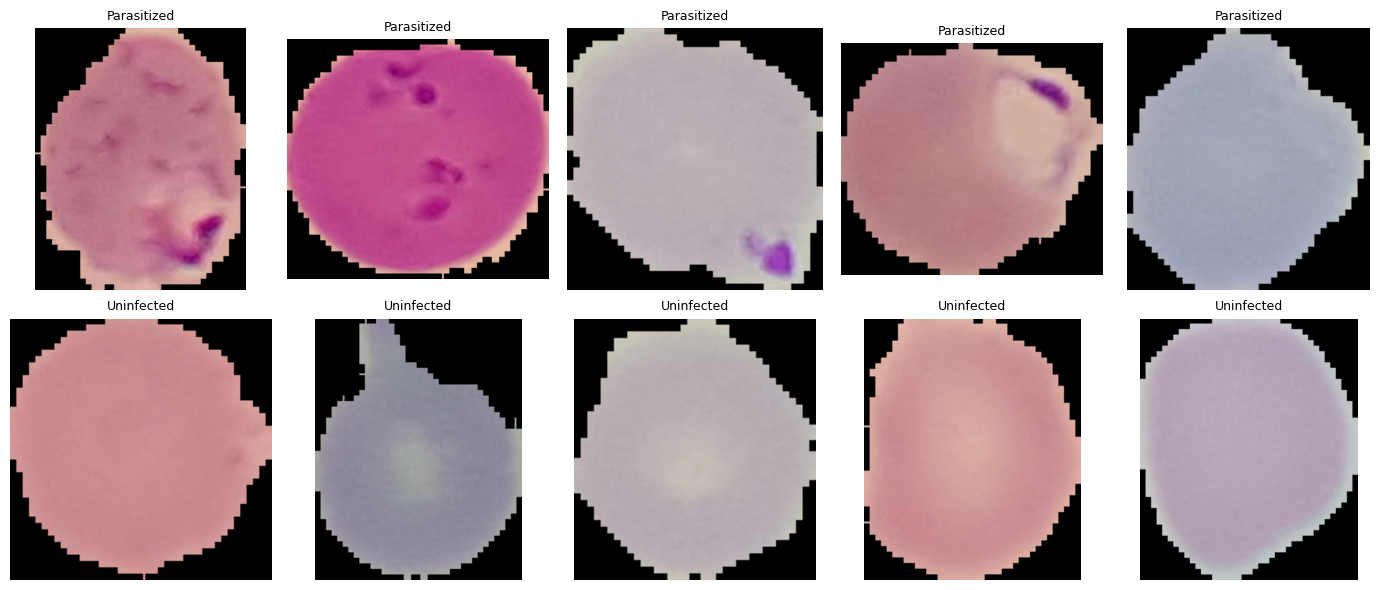

In [4]:
sample = train_df.sample(min(300, len(train_df)), random_state=0)
info = []
for p in sample['path']:
    with Image.open(p) as im:
        info.append({'w': im.size[0], 'h': im.size[1], 'mode': im.mode})
info = pd.DataFrame(info)
print(info.describe().round(0).loc[['min', '50%', 'max']])
print('Colour modes:', info['mode'].value_counts().to_dict())

fig, axes = plt.subplots(len(classes), 5, figsize=(14, 3 * len(classes)))
axes = np.atleast_2d(axes)
for r, c in enumerate(classes):
    paths = train_df[train_df.label == c]['path'].sample(5, random_state=1)
    for ax, p in zip(axes[r], paths):
        ax.imshow(Image.open(p).convert('RGB'))
        ax.set_title(c, fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

## 1. Data Understanding and Audit

> **Summary:** The dataset holds 27,558 RGB cell images, perfectly balanced across two classes, drawn from 200 patients whose class mix is uneven.

### Key Findings

| Aspect | Result |
|---|---|
| Total images | 27,558 |
| Class distribution | Parasitized 13,779 / Uninfected 13,779 (max / min = 1.0) |
| Colour mode | RGB for all 300 sampled images |
| Width (min / median / max) | 61 / 130 / 229 px |
| Height (min / median / max) | 82 / 133 / 187 px |
| Patients identified | 200 (0 files unmatched), 137.79 images per patient on average |
| Largest patients | C68 (702), C39 (687), C132 (639), C99 (632), C182 (614) |
| Patients with both classes | 150 |
| Patients with Uninfected only | 50 |
| Patients with Parasitized only | 0 |
| Classes found / device | Parasitized, Uninfected / cuda (GPU) |

### Visual Inspection
Four of the five Parasitized samples show dark purple marks (a spot at the lower right, several spots on a magenta cell, a streak at the upper right); the fifth, a blue-grey cell, shows no visible mark. Uninfected samples are smooth and plain. In both rows the stain colour varies from pink and magenta to blue-grey and grey-white, and every cell sits on black padding with a stair-step outline.

### Interpretation
- The classes are balanced and all images are colour, so no imbalance handling or grey-scale conversion is needed.
- The purple stain may be part of the real evidence, so colour is kept.
- Stain colour and padding vary between slides, not with the label, which makes them likely shortcut candidates. The 50 Uninfected-only patients raise this risk, because a model could link their slide appearance to the label "Uninfected".

### Action Taken
- Keep `GRAYSCALE = False` and resize all images to 224 x 224.
- Split the data by patient id, since each patient contributes about 138 cells from one slide.
- Test for background and outline shortcuts with Grad-CAM in Section 6.

In [5]:
def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

t0 = time.time()
train_df['size'] = [os.path.getsize(p) for p in train_df['path']]
print(f'Sizes read in {time.time() - t0:.0f}s', flush=True)

same_size = train_df[train_df.duplicated('size', keep=False)]
print('Files sharing a size with another file:', len(same_size), flush=True)

train_df['md5'] = train_df['path']          # unique placeholder = no duplicate
hashes = []
for i, p in enumerate(same_size['path']):
    hashes.append(md5(p))
    if (i + 1) % 2000 == 0:
        print(f'  hashed {i + 1} / {len(same_size)}  ({time.time() - t0:.0f}s)', flush=True)
train_df.loc[same_size.index, 'md5'] = hashes

dup = train_df[train_df.duplicated('md5', keep=False)]
print('Files that belong to a duplicate set:', len(dup))
print('Duplicate sets:', dup['md5'].nunique())
print('Extra copies (would be removed):', train_df.duplicated('md5').sum())

if len(dup):
    labels_per_set = dup.groupby('md5')['label'].nunique()
    patients_per_set = dup.groupby('md5')['group'].nunique()
    print('Sets with conflicting labels:', (labels_per_set > 1).sum())
    print('Sets spanning more than one patient:', (patients_per_set > 1).sum())

    sets = list(dup.groupby('md5'))[:4]
    fig, axes = plt.subplots(len(sets), 2, figsize=(6, 3 * len(sets)))
    axes = np.atleast_2d(axes)
    for ax_row, (h, g) in zip(axes, sets):
        for ax, (_, r) in zip(ax_row, g.head(2).iterrows()):
            ax.imshow(Image.open(r['path']).convert('RGB'))
            ax.set_title(f"{r['label']}\n{r['file']}", fontsize=7)
            ax.axis('off')
    plt.tight_layout()
    plt.show()

Sizes read in 6s
Files sharing a size with another file: 23699
  hashed 2000 / 23699  (136s)
  hashed 4000 / 23699  (259s)
  hashed 6000 / 23699  (362s)
  hashed 8000 / 23699  (465s)
  hashed 10000 / 23699  (571s)
  hashed 12000 / 23699  (678s)
  hashed 14000 / 23699  (785s)
  hashed 16000 / 23699  (891s)
  hashed 18000 / 23699  (997s)
  hashed 20000 / 23699  (1103s)
  hashed 22000 / 23699  (1211s)
Files that belong to a duplicate set: 0
Duplicate sets: 0
Extra copies (would be removed): 0


In [6]:
# Backup so a restart does not cost the 12-minute hashing again
train_df.to_csv('/kaggle/working/train_df_md5.csv', index=False)

# Validation split BY PATIENT: no patient appears in both train and val
sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(train_df, train_df['label'], train_df['group']))
tr_df = train_df.iloc[tr_idx].reset_index(drop=True)
va_df = train_df.iloc[va_idx].reset_index(drop=True)

if not TEST_DIR:                                   # carve a grouped test set
    tr_idx, te_idx = next(sgkf.split(tr_df, tr_df['label'], tr_df['group']))
    tr_df, test_df = (tr_df.iloc[tr_idx].reset_index(drop=True),
                      tr_df.iloc[te_idx].reset_index(drop=True))

print(f'train {len(tr_df)} | val {len(va_df)} | test {len(test_df)}')
print('Patients per split:', tr_df.group.nunique(), '|',
      va_df.group.nunique(), '|', test_df.group.nunique())
print('Groups shared by train and val :', len(set(tr_df.group) & set(va_df.group)))   # must be 0
print('Groups shared by train and test:', len(set(tr_df.group) & set(test_df.group)))  # must be 0
print('Groups shared by val and test  :', len(set(va_df.group) & set(test_df.group)))  # must be 0
for name, d in [('train', tr_df), ('val', va_df), ('test', test_df)]:
    print(name, d['label'].value_counts().to_dict())

train 19118 | val 5105 | test 3335
Patients per split: 139 | 33 | 28
Groups shared by train and val : 0
Groups shared by train and test: 0
Groups shared by val and test  : 0
train {'Parasitized': 9586, 'Uninfected': 9532}
val {'Parasitized': 2853, 'Uninfected': 2252}
test {'Uninfected': 1995, 'Parasitized': 1340}


  train: 5000 / 19118 (8s)
  train: 10000 / 19118 (13s)
  train: 15000 / 19118 (18s)
  val: 5000 / 5105 (6s)
test: near-duplicate in train at <0.10: 234 of 3335 | at <0.05: 0 | closest 5: [0.065 0.067 0.068 0.07  0.07 ]
val: near-duplicate in train at <0.10: 249 of 5105 | at <0.05: 0 | closest 5: [0.064 0.069 0.07  0.07  0.072]


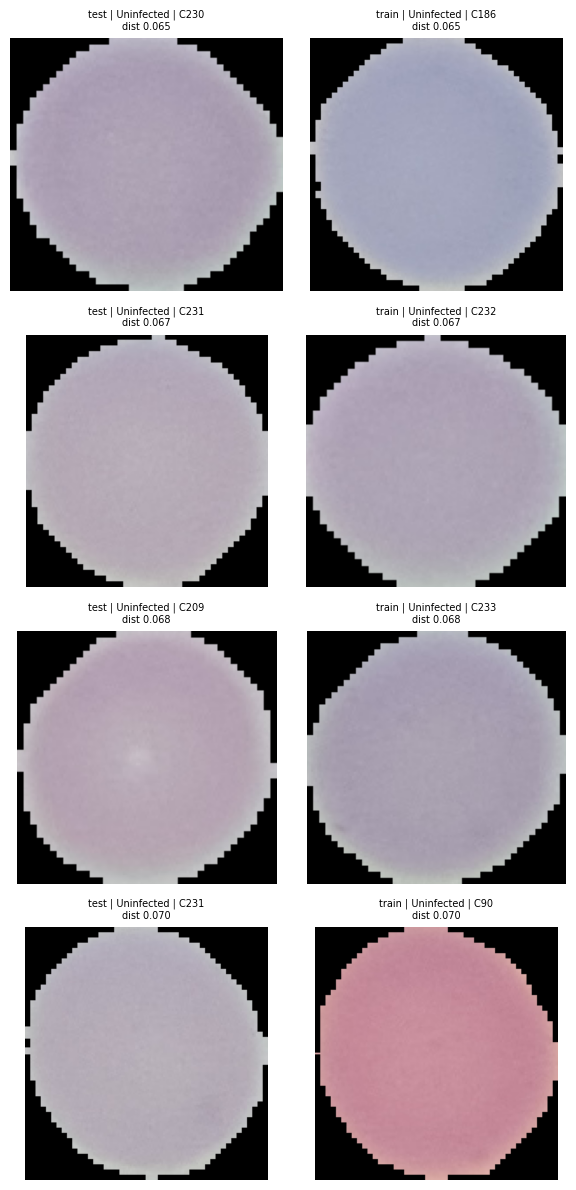

In [7]:
from concurrent.futures import ThreadPoolExecutor

def fingerprint(path, n=32):
    with Image.open(path) as im:
        a = np.asarray(im.convert('L').resize((n, n)), dtype=np.float32)
    return ((a - a.mean()) / (a.std() + 1e-6)).flatten()

def fingerprints(paths, name):
    t0, out = time.time(), []
    with ThreadPoolExecutor(max_workers=32) as ex:
        for i, f in enumerate(ex.map(fingerprint, paths)):
            out.append(f)
            if (i + 1) % 5000 == 0:
                print(f'  {name}: {i + 1} / {len(paths)} ({time.time() - t0:.0f}s)', flush=True)
    return np.stack(out)

tr_fp = fingerprints(tr_df['path'].tolist(), 'train')
te_fp = fingerprints(test_df['path'].tolist(), 'test')
va_fp = fingerprints(va_df['path'].tolist(), 'val')

def nearest(q, ref):
    d = torch.cdist(torch.tensor(q).to(device), torch.tensor(ref).to(device), p=1) / q.shape[1]
    return d.min(dim=1)

te_d, te_j = nearest(te_fp, tr_fp)
va_d, va_j = nearest(va_fp, tr_fp)
for name, d in [('test', te_d), ('val', va_d)]:
    d = d.cpu().numpy()
    print(f'{name}: near-duplicate in train at <0.10: {(d < 0.10).sum()} of {len(d)}'
          f' | at <0.05: {(d < 0.05).sum()}'
          f' | closest 5: {np.sort(d)[:5].round(3)}')

# Show the 4 closest test-vs-train pairs side by side
order = te_d.argsort()[:4].tolist()
fig, axes = plt.subplots(4, 2, figsize=(6, 12))
for row, i in zip(axes, order):
    j = int(te_j[i])
    for ax, r, tag in zip(row, [test_df.iloc[i], tr_df.iloc[j]], ['test', 'train']):
        ax.imshow(Image.open(r['path']).convert('RGB'))
        ax.set_title(f"{tag} | {r['label']} | {r['group']}\ndist {te_d[i]:.3f}", fontsize=7)
        ax.axis('off')
plt.tight_layout()
plt.show()

## 2. Leakage Checks and Patient-Level Split

> **Summary:** No exact duplicates, no near-duplicates at the 0.05 threshold, and no patient appears in more than one split.

### Exact Duplicate Check
Files were compared by size first and hashed with MD5 only when another file had the same size (identical files must have identical sizes).

| Measure | Result |
|---|---|
| Time to read all file sizes | 6 s |
| Files sharing a size with another file (hashed) | 23,699 |
| Hashing time | about 20 minutes |
| Files in duplicate sets | 0 |
| Duplicate sets / extra copies | 0 / 0 |

### Near-Duplicate Check
Each image was reduced to a 32 x 32 standardized grey-scale fingerprint and compared with its nearest training image.

| Split | Images | Below 0.10 | Below 0.05 | Five closest distances |
|---|---|---|---|---|
| Test | 3,335 | 234 | 0 | 0.065, 0.067, 0.068, 0.070, 0.070 |
| Validation | 5,105 | 249 | 0 | 0.064, 0.069, 0.070, 0.070, 0.072 |

The four closest test-train pairs are all Uninfected cells from different patients (C230 / C186, C231 / C232, C209 / C233, C231 / C90). They are round, pale, plain cells that differ in stain colour, and the last pair is pale grey against clear pink, so they are look-alikes and not copies.

### Patient-Level Split
`StratifiedGroupKFold` with 6 folds was used for validation, then once more on the remaining data for test.

| Split | Images | Patients | Parasitized | Uninfected | Parasitized share |
|---|---|---|---|---|---|
| Train | 19,118 | 139 | 9,586 | 9,532 | 50.1% |
| Validation | 5,105 | 33 | 2,853 | 2,252 | 55.9% |
| Test | 3,335 | 28 | 1,340 | 1,995 | 40.2% |

Shared patients: train-validation 0, train-test 0, validation-test 0.

### Interpretation
- The 0.10 flags come from plain pale cells that look alike in grey-scale, since the fingerprint ignores colour. Nothing is flagged at 0.05.
- A grouped split cannot force an equal class mix, so validation (55.9%) and test (40.2%) differ in prevalence.

### Action Taken
- No image was removed, and the patient-level split is kept.
- PPV is reported at the test prevalence and recomputed for 5% and 1%.

### Why Not a Random Split?
With about 138 cells per patient, a random split puts cells from the same patient, slide and background in both training and test. The model could then score well by recognising the slide instead of the parasite, and the test score would be higher than the score on new patients.

In [8]:
from concurrent.futures import ThreadPoolExecutor

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
to_rgb = [transforms.Grayscale(num_output_channels=3)] if GRAYSCALE else []

train_tf = transforms.Compose(to_rgb + [
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(),      # added: a cell has no left or right
    transforms.RandomVerticalFlip(),        # added: a cell has no up or down
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose(to_rgb + [
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

def load_img(p):
    with Image.open(p) as im:
        return im.convert('L' if GRAYSCALE else 'RGB')   # returns an in-memory copy

class ImageTable(Dataset):
    def __init__(self, df, tf):
        self.paths = df['path'].tolist()
        self.y = df['label'].map({c: i for i, c in enumerate(classes)}).tolist()
        self.tf = tf
        t0 = time.time()
        with ThreadPoolExecutor(max_workers=32) as ex:
            self.imgs = list(ex.map(load_img, self.paths))   # preload into RAM
        print(f'  loaded {len(self.imgs)} images in {time.time() - t0:.0f}s', flush=True)
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return self.tf(self.imgs[i]), self.y[i]

print('train'); train_ds = ImageTable(tr_df, train_tf)
print('val');   val_ds = ImageTable(va_df, eval_tf)
print('test');  test_ds = ImageTable(test_df, eval_tf)

train
  loaded 19118 images in 14s
val
  loaded 5105 images in 4s
test
  loaded 3335 images in 2s


In [9]:
n_c = np.bincount(train_ds.y, minlength=len(classes))
class_w = len(train_ds) / (len(classes) * n_c)        # N / (K * n_c)
print('n_c:', dict(zip(classes, n_c)))
print('weights:', dict(zip(classes, class_w.round(3))))
loss_w = torch.tensor(class_w, dtype=torch.float32, device=device)

USE_SAMPLER = False     # try True: balanced batches instead of weighted loss
if USE_SAMPLER:
    sample_w = class_w[train_ds.y]                    # P(i) ~ 1 / n_class(i)
    sampler = WeightedRandomSampler(sample_w, len(sample_w), replacement=True)
    train_dl = DataLoader(train_ds, 32, sampler=sampler, num_workers=2)
    loss_w = None
else:
    train_dl = DataLoader(train_ds, 32, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, 64, num_workers=2)
test_dl = DataLoader(test_ds, 64, num_workers=2)

xb, yb = next(iter(train_dl))
print('One batch:', tuple(xb.shape), '| labels:', yb[:8].tolist())

n_c: {'Parasitized': np.int64(9586), 'Uninfected': np.int64(9532)}
weights: {'Parasitized': np.float64(0.997), 'Uninfected': np.float64(1.003)}
One batch: (32, 3, 224, 224) | labels: [0, 0, 1, 0, 0, 1, 0, 0]


## 3. Preprocessing, Augmentation and Class Weights

> **Summary:** Class weights are almost equal (0.997 and 1.003), flips were added to the augmentation, and all 27,558 images are preloaded into memory.

### Class Weights
Weight = N / (K x n_c), with N = 19,118 and K = 2.

| Class | Training images | Calculation | Weight |
|---|---|---|---|
| Parasitized | 9,586 | 19,118 / (2 x 9,586) = 19,118 / 19,172 | 0.997 |
| Uninfected | 9,532 | 19,118 / (2 x 9,532) = 19,118 / 19,064 | 1.003 |

Imbalance strategy: weighted loss (`USE_SAMPLER = False`).

### Training Augmentation

| Transform | Setting | Reason |
|---|---|---|
| Random resized crop | scale 0.8 to 1.0, output 224 x 224 | Small changes in framing |
| Random rotation | up to 10 degrees | Cells have no fixed orientation |
| Horizontal and vertical flip | added | A blood cell has no left-right or up-down direction |
| Colour jitter | brightness 0.15, contrast 0.15 | Mild stain variation; hue and saturation left unchanged |

Validation and test images are only resized to 224 x 224 and normalized with ImageNet mean and standard deviation.

### Data Loading

| Split | Images | Load time |
|---|---|---|
| Train | 19,118 | 14 s |
| Validation | 5,105 | 4 s |
| Test | 3,335 | 2 s |

A training batch has shape (32, 3, 224, 224), and its first labels are [0, 0, 1, 0, 0, 1, 0, 0], where 0 = Parasitized.

### Interpretation and Action Taken
- With weights this close to 1.0 the loss is effectively unweighted. They are kept because they cost nothing and protect against an uneven split.
- Hue and saturation jitter was avoided because the purple stain may be real evidence.
- Preloading images into RAM keeps each epoch near 42 s, since reading files from disk every epoch would be much slower.

In [10]:
def build_model(name, n_classes):
    if name == 'resnet18':
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'resnet50':
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'efficientnet_b0':
        w = models.EfficientNet_B0_Weights.DEFAULT
        m = models.efficientnet_b0(weights=w)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)
        body, head, last = m, m.classifier, m.features[-1]
    else:
        raise ValueError(name)
    for p in body.parameters():
        p.requires_grad = False
    for p in head.parameters():
        p.requires_grad = True
    return m.to(device), head, last

model, head, last_block = build_model(BACKBONE, len(classes))
print(BACKBONE, 'trainable:',
      sum(p.numel() for p in model.parameters() if p.requires_grad))
print(BACKBONE, 'total    :', sum(p.numel() for p in model.parameters()))

def predict(model, loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(F.softmax(model(xb.to(device)), 1).cpu())
            ys.append(yb)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

def fit(model, params, epochs, lr):
    opt = torch.optim.Adam(params, lr=lr)
    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb, weight=loss_w)
            opt.zero_grad()
            loss.backward()
            opt.step()
        p, y = predict(model, val_dl)
        macro = f1_score(y, p.argmax(1), average='macro')     # not accuracy
        if macro > best:
            best, best_state = macro, copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: val macro-F1 {macro:.3f} '
              f'({time.time() - t0:.0f}s)', flush=True)
    model.load_state_dict(best_state)
    return best

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 195MB/s]


resnet18 trainable: 1026
resnet18 total    : 11177538


In [11]:
print('Phase 1: head only')
best1 = fit(model, head.parameters(), epochs=2, lr=1e-3)
print(f'Best validation macro-F1, phase 1: {best1:.3f}')

Phase 1: head only
epoch 1: val macro-F1 0.866 (42s)
epoch 2: val macro-F1 0.846 (42s)
Best validation macro-F1, phase 1: 0.866


In [12]:
print('Phase 2: fine-tune the last block')
for p in last_block.parameters():
    p.requires_grad = True
print('Trainable now:', sum(p.numel() for p in model.parameters() if p.requires_grad))
best2 = fit(model, [{'params': last_block.parameters(), 'lr': 1e-4},
                    {'params': head.parameters(), 'lr': 1e-3}], epochs=3, lr=1e-3)
print(f'Best validation macro-F1, phase 2: {best2:.3f}')

Phase 2: fine-tune the last block
Trainable now: 8394754
epoch 1: val macro-F1 0.934 (41s)
epoch 2: val macro-F1 0.937 (41s)
epoch 3: val macro-F1 0.936 (42s)
Best validation macro-F1, phase 2: 0.937


## 4. Two-Phase Training

> **Summary:** Fine-tuning the last block raised validation macro-F1 from 0.866 to 0.937 in 5 epochs, about 3.5 minutes of training.

### Model and Trainable Parameters
ResNet-18 pretrained on ImageNet, with a new 2-class head (11,177,538 parameters in total).

| Phase | Trainable layers | Trainable parameters | Share of network |
|---|---|---|---|
| 1 | Head only | 1,026 | 0.009% |
| 2 | `layer4` + head (learning rates 1e-4 and 1e-3) | 8,394,754 | 75.1% |

### Validation Results

| Phase | Epoch | Validation macro-F1 | Time |
|---|---|---|---|
| 1 | 1 | 0.866 | 42 s |
| 1 | 2 | 0.846 | 42 s |
| 2 | 1 | 0.934 | 41 s |
| 2 | 2 | **0.937** | 41 s |
| 2 | 3 | 0.936 | 42 s |

- Best of Phase 1: 0.866. Best of Phase 2: 0.937 (epoch 2).
- Gain from fine-tuning: 0.937 - 0.866 = **+0.071** macro-F1.
- Total training time: 208 s (about 3.5 minutes).
- The best epoch of each phase was selected by validation macro-F1, and the test set was not used.

### Interpretation
Frozen ImageNet features were not enough, because parasite spots and stain are specific to blood cells. Unfreezing `layer4` let the network adapt to them. In Phase 2 the score stayed between 0.934 and 0.937, so the model has levelled off and more epochs with the same settings would add little.

### Next Step
Use the best Phase 2 weights for the test evaluation. With more time, a lower learning rate in the last epochs, unfreezing `layer3`, or comparing the sampler with the weighted loss would be better than training longer.

              precision    recall  f1-score   support

 Parasitized      0.963     0.962     0.963      1340
  Uninfected      0.974     0.975     0.975      1995

    accuracy                          0.970      3335
   macro avg      0.969     0.969     0.969      3335
weighted avg      0.970     0.970     0.970      3335

Macro-F1: 0.969
Accuracy: 0.97


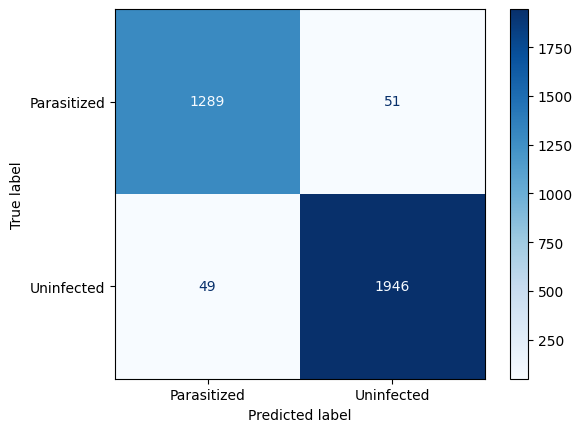

[[1289   51]
 [  49 1946]]


In [13]:
p_test, y_test = predict(model, test_dl)
pred = p_test.argmax(1)
print(classification_report(y_test, pred, target_names=classes, digits=3))
print('Macro-F1:', round(f1_score(y_test, pred, average='macro'), 3))
print('Accuracy:', round((pred == y_test).mean(), 3))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=classes).plot(cmap='Blues')
plt.show()
print(confusion_matrix(y_test, pred))

In [14]:
if len(classes) == 2:
    pos = classes.index(POSITIVE)
    p_val, y_val = predict(model, val_dl)
    fpr, tpr, thr = roc_curve(y_val == pos, p_val[:, pos])
    t = thr[np.argmax(tpr >= TARGET_RECALL)]          # highest t reaching target
    print(f'Threshold chosen on VALIDATION for recall >= {TARGET_RECALL}: {t:.3f}')

    # What that threshold gives on validation (where it was set)
    yv, sv = (y_val == pos), (p_val[:, pos] >= t)
    print(f'Validation recall at t: {(sv & yv).sum() / yv.sum():.3f} | '
          f'specificity: {(~sv & ~yv).sum() / (~yv).sum():.3f}')

    # Applied once to the test set
    s = p_test[:, pos]
    yp, yt = s >= t, y_test == pos
    tp, fn = (yp & yt).sum(), (~yp & yt).sum()
    tn, fp = (~yp & ~yt).sum(), (yp & ~yt).sum()
    sens, spec = tp / (tp + fn), tn / (tn + fp)
    ppv = tp / max(tp + fp, 1)
    prev = yt.mean()
    print(f'Test AUC {roc_auc_score(yt, s):.3f}')
    print(f'TP {tp}  FN {fn}  TN {tn}  FP {fp}')
    print(f'Sensitivity {sens:.3f}   Specificity {spec:.3f}   PPV {ppv:.3f}')
    print(f'Test-set prevalence: {prev:.3f}')

    # PPV = sens*prev / (sens*prev + (1-spec)*(1-prev))
    for pr in [prev, 0.05, 0.01]:
        v = sens * pr / (sens * pr + (1 - spec) * (1 - pr))
        print(f'PPV at prevalence {pr:.3f}: {v:.3f}')

Threshold chosen on VALIDATION for recall >= 0.95: 0.160
Validation recall at t: 0.950 | specificity: 0.936
Test AUC 0.994
TP 1316  FN 24  TN 1878  FP 117
Sensitivity 0.982   Specificity 0.941   PPV 0.918
Test-set prevalence: 0.402
PPV at prevalence 0.402: 0.918
PPV at prevalence 0.050: 0.468
PPV at prevalence 0.010: 0.145


## 5. Test Evaluation and Threshold Selection

> **Summary:** The model reaches test macro-F1 0.969 and AUC 0.994. At threshold 0.160 it catches 98.2% of infected cells, but PPV falls from 0.918 to 0.468 when only 5% of cells are infected.

### Performance at the Default 0.5 Cut-off
Test set: 3,335 cells from 28 patients, used once.

| Class | Precision | Recall | F1 | Support |
|---|---|---|---|---|
| Parasitized | 0.963 | 0.962 | 0.963 | 1,340 |
| Uninfected | 0.974 | 0.975 | 0.975 | 1,995 |
| Accuracy / macro-F1 | | | 0.970 / 0.969 | 3,335 |

| Confusion matrix | Predicted Parasitized | Predicted Uninfected |
|---|---|---|
| **True Parasitized** | 1,289 | 51 |
| **True Uninfected** | 49 | 1,946 |

### Threshold Chosen for High Recall
The threshold **0.160** was chosen on the validation set for recall of at least 0.95 (validation recall 0.950, specificity 0.936) and applied once to the test set.

| Metric | Calculation | Value |
|---|---|---|
| True / false positives | | TP 1,316, FP 117 |
| True / false negatives | | TN 1,878, FN 24 |
| Sensitivity | 1,316 / 1,340 | 0.982 |
| Specificity | 1,878 / 1,995 | 0.941 |
| PPV | 1,316 / 1,433 | 0.918 |
| AUC | | 0.994 |

### Effect of the Threshold

| Threshold | Missed infections | False alarms |
|---|---|---|
| 0.5 (default) | 51 | 49 |
| 0.160 | 24 | 117 |

### PPV at Different Prevalence Levels
PPV = (sens x prev) / (sens x prev + (1 - spec) x (1 - prev)), with false-positive rate 117 / 1,995 = 0.0586.

| Prevalence | Calculation | PPV |
|---|---|---|
| 40.2% (test set) | 1,316 / 1,433 | 0.918 |
| 5% | 0.0491 / (0.0491 + 0.0557) | 0.468 |
| 1% | 0.0098 / (0.0098 + 0.0580) | 0.145 |

### Interpretation
- Lowering the threshold halves the missed infections (51 to 24) at the cost of more false alarms (49 to 117), which is the right trade when a missed infection is the costlier error.
- Sensitivity and specificity do not change with prevalence, but PPV does. At low prevalence there are many more uninfected cells, so even a 5.9% false-positive rate creates many false alarms beside a few true positives.
- A positive result should be confirmed by a microscopist and not treated as a diagnosis.

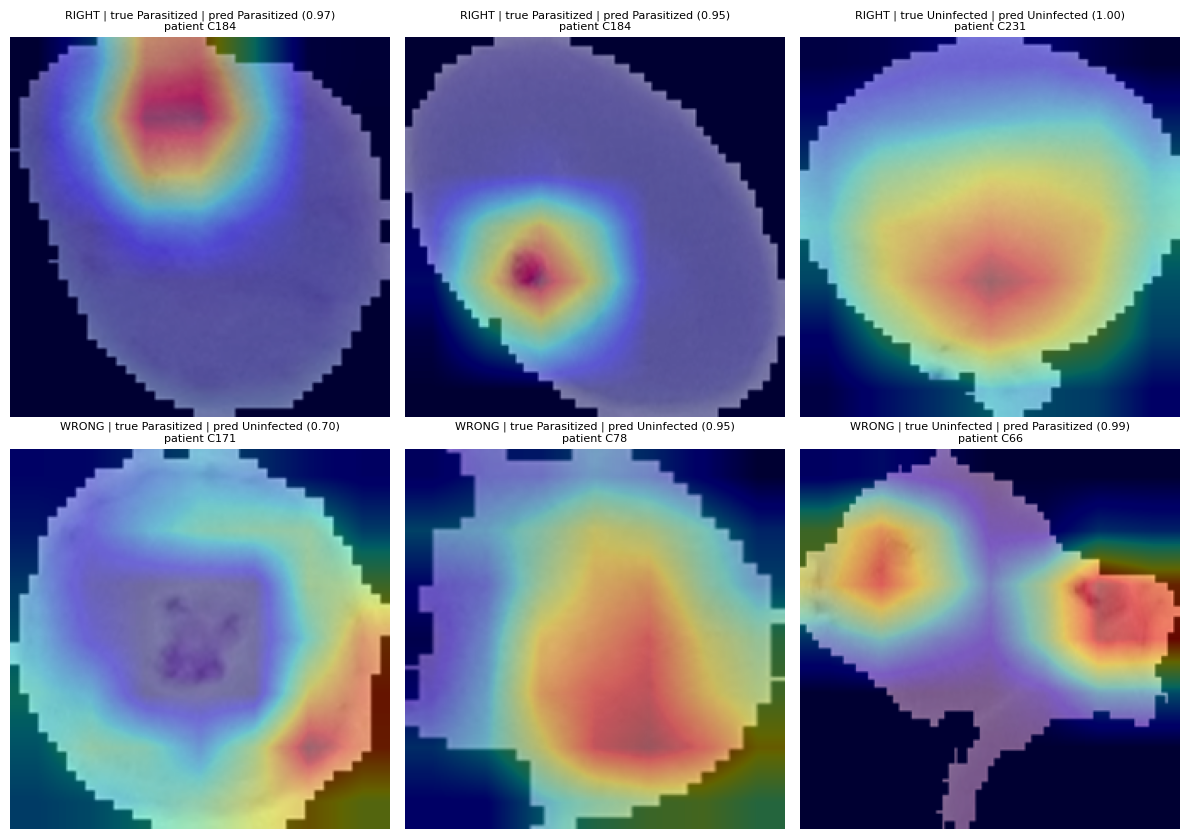

In [15]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._save_act)
        layer.register_full_backward_hook(self._save_grad)
    def _save_act(self, m, i, o):
        self.acts = o.detach()
    def _save_grad(self, m, gi, go):
        self.grads = go[0].detach()
    def __call__(self, x, cls=None):
        self.model.eval()
        x = x.unsqueeze(0).to(device).requires_grad_(True)
        logits = self.model(x)
        cls = int(logits.argmax()) if cls is None else cls
        self.model.zero_grad()
        logits[0, cls].backward()
        alpha = self.grads.mean(dim=(2, 3), keepdim=True)        # (1/Z) sum dy/dA
        cam = F.relu((alpha * self.acts).sum(1)).squeeze()       # ReLU(sum a*A)
        cam = F.interpolate(cam[None, None], size=x.shape[-2:],
                            mode='bilinear').squeeze()
        return (cam / (cam.max() + 1e-8)).cpu().numpy(), cls

for p in model.parameters():
    p.requires_grad = True
cam = GradCAM(model, last_block)

rng = np.random.RandomState(0)
def pick(mask, k):
    return rng.choice(np.where(mask)[0], k, replace=False).tolist()

P = classes.index(POSITIVE)
U = 1 - P
right = (pick((pred == y_test) & (y_test == P), 2)
         + pick((pred == y_test) & (y_test == U), 1))
wrong = (pick((pred != y_test) & (y_test == P), 2)
         + pick((pred != y_test) & (y_test == U), 1))

fig, axes = plt.subplots(2, 3, figsize=(12, 8.5))
for ax, i, tag in zip(axes.flat, right + wrong, ['RIGHT'] * 3 + ['WRONG'] * 3):
    x, y = test_ds[i]
    heat, c = cam(x)
    ax.imshow(test_ds.imgs[i].resize((IMG_SIZE,) * 2))
    ax.imshow(heat, cmap='jet', alpha=0.4)
    ax.set_title(f'{tag} | true {classes[y]} | pred {classes[c]} ({p_test[i][c]:.2f})\n'
                 f'patient {test_df.iloc[i]["group"]}', fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

In [16]:
rng2 = np.random.RandomState(1)
sel = rng2.choice(len(test_ds), 300, replace=False)
rows = []
for i in sel:
    x, y = test_ds[i]
    heat, c = cam(x)
    gray = np.array(test_ds.imgs[i].convert('L').resize((IMG_SIZE, IMG_SIZE)))
    bg = gray < 10                                   # black padding around the cell
    rows.append({'true': classes[y],
                 'bg_pixels': bg.mean(),             # share of the image that is background
                 'bg_attention': heat[bg].sum() / (heat.sum() + 1e-8)})
r = pd.DataFrame(rows)
print(r.groupby('true')[['bg_pixels', 'bg_attention']].mean().round(3))
print('Overall:', r[['bg_pixels', 'bg_attention']].mean().round(3).to_dict())

             bg_pixels  bg_attention
true                                
Parasitized      0.272         0.121
Uninfected       0.262         0.163
Overall: {'bg_pixels': 0.266, 'bg_attention': 0.145}


## 6. Explainability with Grad-CAM

> **Summary:** The heatmaps mostly sit on the cell, with 14.5% of the attention on the background against 26.6% of the pixels. A mild shortcut is suspected but not confirmed.

### Background Attention Check
Based on 300 random test images.

| Class | Background share of pixels | Background share of attention | Attention / pixel share |
|---|---|---|---|
| Parasitized | 0.272 | 0.121 | 0.44 |
| Uninfected | 0.262 | 0.163 | 0.62 |
| Overall | 0.266 | 0.145 | 0.55 |

### Heatmap Review
Layer4 Grad-CAM, 7 x 7 map scaled up to the image.

| # | Outcome | True / predicted (confidence) | Patient | Observation |
|---|---|---|---|---|
| 1 | Correct | Parasitized / Parasitized (0.97) | C184 | Red column of heat at the top of the cell reaching toward the upper edge; no parasite is visible under it, so it is not solid evidence |
| 2 | Correct | Parasitized / Parasitized (0.95) | C184 | Small, tight red spot on a dark mark in the lower left of the cell; legitimate parasite evidence |
| 3 | Correct | Uninfected / Uninfected (1.00) | C231 | Wide warm area over the lower middle of the plain cell body and nothing on the padding |
| 4 | Error | Parasitized / Uninfected (0.70) | C171 | Purple cluster in the centre gets almost no heat; the strongest heat is on the rim at the lower right, so the parasite was missed |
| 5 | Error | Parasitized / Uninfected (0.95) | C78 | Heat covers the middle and lower part of an angular, irregular cell; no clear parasite is visible, and the model is confidently wrong |
| 6 | Error | Uninfected / Parasitized (0.99) | C66 | Cell with two lobes and a thin tail; strongest heat on the two lobes, the right one touching the padding, so the odd outline probably caused the false alarm |

### Interpretation
- **Against a strong shortcut:** the background gets less attention than its share of the pixels in both classes, and heatmap 2 sits on a real parasite spot.
- **For a mild shortcut:** Uninfected predictions put more attention on the background than Parasitized ones (0.163 against 0.121), three of six maps (1, 4 and 6) peak near the cell edge, and both confident errors on odd-shaped cells (5 and 6) suggest the outline may act as a clue.
- With only six heatmaps and 300 attention scores, this is a suspicion and not a confirmed shortcut.

**Verdict: shortcut suspected (mild), not confirmed.**

### Proposed Follow-up Experiment
Paint the padding and the outer ring of every test cell with one fixed colour and re-score at the same threshold of 0.160. A sharp fall in sensitivity (0.982) or specificity (0.941) would show reliance on the outline. The test can then be repeated with grey-scale images to check the second suspect from Section 1, the stain colour.

In [17]:
torch.save({'state_dict': model.state_dict(), 'classes': classes,
            'backbone': BACKBONE, 'img_size': IMG_SIZE,
            'grayscale': GRAYSCALE}, '/kaggle/working/week6_model.pt')
print('Saved week6_model.pt')

# Check the file loads and holds what we expect
ck = torch.load('/kaggle/working/week6_model.pt', map_location='cpu')
print(sorted(ck.keys()))
print(ck['classes'], ck['backbone'], ck['img_size'], ck['grayscale'])
print(f"File size: {os.path.getsize('/kaggle/working/week6_model.pt') / 1e6:.1f} MB")

Saved week6_model.pt
['backbone', 'classes', 'grayscale', 'img_size', 'state_dict']
['Parasitized', 'Uninfected'] resnet18 224 False
File size: 44.8 MB


## 7. Model Export

> **Summary:** The fine-tuned ResNet-18 is saved as `week6_model.pt` (44.8 MB) together with the settings needed to preprocess new images.

| Item | Detail |
|---|---|
| File | `/kaggle/working/week6_model.pt` |
| Size | 44.8 MB |
| Stored keys (5) | `backbone`, `classes`, `grayscale`, `img_size`, `state_dict` |
| Reload check | `['Parasitized', 'Uninfected']`, `resnet18`, 224, `grayscale = False` |
| Weights | Fine-tuned ResNet-18 (11,177,538 parameters), best Phase 2 epoch (epoch 2, validation macro-F1 0.937) |
| Not stored | Decision threshold 0.160 |

### Notes
- The model was saved only after the test, threshold and Grad-CAM checks, so the file matches the reported results (macro-F1 0.969, sensitivity 0.982, specificity 0.941).
- The threshold of 0.160 must be applied separately (for example, documented in a README), because the default 0.5 would miss 51 infections instead of 24.

## 8. Review Questions

### Q1. Why does a random split of chest X-rays overestimate performance?
**Answer:** The same patient often has several X-rays with the same body, scanner and image quality. A random split places some in training and the rest in test, so the model can score well by recognising the patient or scanner and not the disease. The result reflects memory of known patients and is higher than the score on new people.

### Q2. Two classes have 900 and 100 training images. Compute both class weights with N / (K x n_c).
**Working:** N = 900 + 100 = 1,000 and K = 2.

| Class | Calculation | Weight |
|---|---|---|
| 900 images | 1,000 / (2 x 900) = 1,000 / 1,800 | **0.556** |
| 100 images | 1,000 / (2 x 100) = 1,000 / 200 | **5.0** |

**Reading:** Each image of the small class counts 9 times as much (5.0 / 0.556 = 9), which cancels the 900 : 100 ratio, so both classes contribute equally to the loss.

### Q3. With focal loss and gamma = 2, by what factor is an example with p_t = 0.8 down-weighted?
**Working:** Focal loss multiplies cross-entropy by (1 - p_t)^gamma, so the factor is (1 - 0.8)^2 = 0.2^2 = **0.04**.

**Reading:** The easy example keeps only 4% of its usual loss (25 times smaller), so well-classified examples barely affect training and hard examples drive learning.

### Q4. Sensitivity 0.90, specificity 0.95, prevalence 2%. Compute PPV.
**Working:** PPV = (sens x prev) / (sens x prev + (1 - spec) x (1 - prev))

| Part | Calculation | Value |
|---|---|---|
| True positives | 0.90 x 0.02 | 0.018 |
| False positives | 0.05 x 0.98 | 0.049 |
| PPV | 0.018 / (0.018 + 0.049) = 0.018 / 0.067 | **0.269** |

**Reading:** Only about 27% of positive results are real, because the disease is rare and the large healthy group produces more false alarms than the small sick group produces true hits.

### Q5. When is macro-F1 a better selection metric than weighted F1?
**Answer:** When classes are imbalanced and the rare class matters, because macro-F1 gives each class an equal say while weighted F1 follows class size.

**Example:** With 900 and 100 images, a model that always predicts the large class has F1 = 0.947 for it and 0 for the small class.

| Metric | Calculation | Value |
|---|---|---|
| Macro-F1 | (0.947 + 0) / 2 | **0.474** |
| Weighted F1 | 0.9 x 0.947 | **0.853** |

Weighted F1 looks good even though the model finds no rare cases.

### Q6. Grad-CAM highlights a hospital label in the corner of X-rays. What do you do next?
**Answer:** The model is using a mark that identifies the hospital and not the lungs, so it should not be deployed.
1. Hide the label on the test images and re-score; a large drop confirms the shortcut.
2. Remove the label from all images and retrain.
3. Check Grad-CAM again.
4. Test on images from a different hospital.